# Cobertura del riesgo cambiario en importaciones

Evaluación de contratos forward a 3 y 6 meses para una importadora de Cartagena

**Toma de decisiones basadas en datos · Universidad Tecnológica de Bolívar**

Ángel Luis Vega Rodríguez (T00068186) · Germán Eduardo De Armas Castaño (T00068765) · María Valentina Serna (T00067756) · Luis Mario Díaz (T00069220) · Daniel Castillo (T00091828)

Este notebook reúne todo el proceso analítico del proyecto, desde la carga de los datos hasta la recomendación. Cada cifra que aparece en el documento técnico y en el tablero sale de una celda de este archivo.

**Contenido**
1. Definición del problema y supuestos
2. ETL (extracción, transformación y carga)
3. Análisis exploratorio
4. Modelado (regresión y volatilidad)
5. Evaluación de decisiones (forward, Monte Carlo, estrategias, tornado y backtest)
6. Recomendación y exportación de resultados

In [1]:
# Librerías y configuración general
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import statsmodels.api as sm
from arch import arch_model
from scipy import stats
from statsmodels.stats.diagnostic import het_arch
from statsmodels.tsa.stattools import adfuller

warnings.filterwarnings("ignore")

RAIZ = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
CRUDOS = RAIZ / "datos" / "crudos"
LIMPIOS = RAIZ / "datos" / "limpios"
FIGURAS = RAIZ / "documento" / "figuras"
RESULTADOS = RAIZ / "resultados"
DATOS_TABLERO = RAIZ / "dashboard" / "datos"
for carpeta in (LIMPIOS, FIGURAS, RESULTADOS, DATOS_TABLERO):
    carpeta.mkdir(parents=True, exist_ok=True)

SEMILLA = 42
N_SIM = 10_000

# Paleta del proyecto
AZUL = "#0B2545"
TURQUESA = "#13A89E"
AMBAR = "#F2A541"
ROJO = "#D1495B"
GRIS = "#8D99AE"
CLARO = "#E9EEF4"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 220, "font.family": "DejaVu Sans", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRIS,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": CLARO, "grid.linewidth": 0.8, "legend.frameon": False,
})


def cop(valor, decimales=0):
    """Formato de pesos colombianos con punto como separador de miles."""
    texto = f"{valor:,.{decimales}f}"
    return "$ " + texto.replace(",", "X").replace(".", ",").replace("X", ".")


def pct(valor, decimales=1):
    """Formato de porcentaje con coma decimal."""
    return f"{valor * 100:.{decimales}f} %".replace(".", ",")


def guardar(figura, nombre):
    """Guarda la figura para el documento técnico."""
    figura.savefig(FIGURAS / f"{nombre}.png", bbox_inches="tight", facecolor="white")


resultados = {}

## 1. Definición del problema

Una importadora mediana de Cartagena compra mercancía a proveedores del exterior y les paga en dólares, mientras que vende en pesos con precios que fija al momento de hacer el pedido. Entre el pedido y el pago pasan entre tres y seis meses. Si el dólar sube en ese tiempo, la compra sale más cara y el margen se reduce, porque el precio de venta ya está comprometido.

La empresa puede fijar hoy la tasa a la que pagará con un contrato forward de compra de dólares con su banco, o puede esperar y pagar a la TRM del día de vencimiento.

**Pregunta de decisión.** ¿Conviene cubrir la compra que se paga dentro de 3 o de 6 meses, y qué porcentaje del monto, dado el riesgo del dólar y su relación con el petróleo y las tasas de interés?

**Métricas.** Costo total de la compra en COP, desviación frente al presupuesto, probabilidad de superar el presupuesto, percentil 95 del costo (VaR) y CVaR, probabilidad de que el margen bruto caiga por debajo del mínimo aceptable y ahorro esperado de cubrir frente a no cubrir.

La empresa es hipotética porque las estadísticas de importaciones del DANE no están disponibles por empresa. Los supuestos de tamaño se fijan con valores razonables para una mediana importadora y todos son editables en el tablero. Los supuestos de mercado (TRM de hoy, presupuesto, tasas y volatilidad) salen de los datos.

In [2]:
# Supuestos de la empresa hipotética (editables en el tablero)
supuestos = {
    "monto_usd": 250_000,       # pago al proveedor en USD
    "margen_objetivo": 0.25,    # margen bruto con el que se fija el precio de venta
    "margen_minimo": 0.15,      # margen bruto mínimo aceptable
    "margen_banco": 0.0015,     # recargo del banco sobre el forward teórico
    "tolerancia_riesgo": 0.05,  # probabilidad máxima aceptada de quedar por debajo del margen mínimo
    "meses_presupuesto": 12,    # ventana para la TRM presupuestada
}
pd.Series(supuestos, name="valor").to_frame()

,valor
monto_usd,250000.0000
margen_objetivo,0.2500
margen_minimo,0.1500
margen_banco,0.0015
tolerancia_riesgo,0.0500
meses_presupuesto,12.0000


## 2. ETL

Las descargas se hacen con `datos/descargar_datos.py`, que guarda copias en `datos/crudos`. Aquí se leen esos archivos, se ajustan tipos y fechas, se revisan duplicados, nulos y valores atípicos y se construyen dos paneles limpios, uno diario y otro mensual.

| Fuente | Serie | Uso en el análisis |
|---|---|---|
| Superfinanciera vía datos.gov.co (`32sa-8pi3`) | TRM oficial diaria | Tasa con la que se liquida la compra |
| Yahoo Finance | USD/COP de mercado (`COP=X`), Brent, WTI, Ecopetrol ADR, índice dólar, S&P 500, oro | Contraste de la TRM, factores externos |
| Banco de Pagos Internacionales (BIS) | Tasa de política del Banco de la República y de la Fed, inflación anual de Colombia y EE. UU. | Precio del forward y contexto macro |
| FRED | Fondos federales y letras a 3 meses | Respaldo opcional; el servidor bloqueó la descarga automática, por eso se usa el BIS |

In [3]:
# Extracción: lectura de los archivos crudos
trm_cruda = pd.read_csv(CRUDOS / "trm_datosgov.csv")
yahoo_crudo = pd.read_csv(CRUDOS / "yahoo_cierres.csv")
bis_crudo = pd.read_csv(CRUDOS / "bis_tasas_inflacion.csv")

for nombre, tabla in {"TRM": trm_cruda, "Yahoo": yahoo_crudo, "BIS": bis_crudo}.items():
    print(f"{nombre}: {tabla.shape[0]:,} filas, {tabla.shape[1]} columnas, tipos {dict(tabla.dtypes.astype(str))}")

TRM: 8,391 filas, 4 columnas, tipos {'valor': 'float64', 'unidad': 'str', 'vigenciadesde': 'str', 'vigenciahasta': 'str'}
Yahoo: 3,099 filas, 8 columnas, tipos {'fecha': 'str', 'brent': 'float64', 'wti': 'float64', 'usdcop_yahoo': 'float64', 'indice_dolar': 'float64', 'ecopetrol_adr': 'float64', 'oro': 'float64', 'sp500': 'float64'}
BIS: 154 filas, 5 columnas, tipos {'mes': 'str', 'tasa_banrep': 'float64', 'tasa_fed': 'float64', 'inflacion_col': 'float64', 'inflacion_eeuu': 'float64'}


In [4]:
# Transformación de la TRM: tipos, duplicados, nulos y periodo de estudio
trm = pd.DataFrame({
    "fecha": pd.to_datetime(trm_cruda["vigenciadesde"]),
    "trm": pd.to_numeric(trm_cruda["valor"], errors="coerce"),
})
calidad_trm = {
    "duplicados": int(trm.duplicated("fecha").sum()),
    "nulos": int(trm["trm"].isna().sum()),
    "no_positivos": int((trm["trm"] <= 0).sum()),
}
trm = (trm.drop_duplicates("fecha").dropna().sort_values("fecha")
          .set_index("fecha").loc["2015-01-01":])
trm["retorno"] = np.log(trm["trm"]).diff()
saltos = trm.loc[trm["retorno"].abs() > 0.04, ["trm", "retorno"]]
print("Calidad TRM:", calidad_trm)
print(f"Periodo: {trm.index.min().date()} a {trm.index.max().date()}, {len(trm):,} observaciones")
print("Variaciones diarias mayores al 4 %:")
print(saltos)

Calidad TRM: {'duplicados': 0, 'nulos': 0, 'no_positivos': 0}
Periodo: 2015-01-03 a 2026-11-21, 2,815 observaciones
Variaciones diarias mayores al 4 %:
                trm   retorno
fecha                        
2020-03-10  3803.60  0.059307
2020-03-13  4034.66  0.050713


In [5]:
# Transformación de Yahoo Finance: fechas, nulos por calendario y valores atípicos de COP=X
yahoo = yahoo_crudo.assign(fecha=pd.to_datetime(yahoo_crudo["fecha"])).set_index("fecha").sort_index()
yahoo = yahoo[~yahoo.index.duplicated()]
print("Nulos por columna antes de alinear:", yahoo.isna().sum().to_dict())

# COP=X se contrasta con la TRM del mismo día para detectar cotizaciones erróneas
contraste = yahoo[["usdcop_yahoo"]].join(trm["trm"], how="inner").dropna()
contraste["diferencia"] = contraste["usdcop_yahoo"] / contraste["trm"] - 1
atipicos_yahoo = contraste.loc[contraste["diferencia"].abs() > 0.03]
print(f"Días con COP=X a más de 3 % de la TRM: {len(atipicos_yahoo)} de {len(contraste):,}")
print(atipicos_yahoo.head(10))
yahoo.loc[atipicos_yahoo.index, "usdcop_yahoo"] = np.nan

Nulos por columna antes de alinear: {'brent': 108, 'wti': 109, 'usdcop_yahoo': 2, 'indice_dolar': 108, 'ecopetrol_adr': 109, 'oro': 109, 'sp500': 109}
Días con COP=X a más de 3 % de la TRM: 14 de 2,226
            usdcop_yahoo      trm  diferencia
fecha                                        
2015-02-20     24.500000  2445.16   -0.989980
2015-03-25    250.000000  2526.79   -0.901060
2015-04-16   2448.100098  2534.63   -0.034139
2015-06-05     26.219999  2588.56   -0.989871
2015-08-11   2641.000000  2913.45   -0.093515
2015-12-03   3007.199951  3166.67   -0.050359
2015-12-10    324.000000  3294.02   -0.901640
2015-12-15     33.139999  3356.00   -0.990125
2016-02-18     33.400002  3391.87   -0.990153
2016-04-19   2898.000000  2995.86   -0.032665


**Lectura.** La TRM llegó sin duplicados ni nulos, y sus únicos saltos diarios mayores al 4 % son de marzo de 2020, al inicio de la pandemia, así que son reales y se conservan. En cambio la serie `COP=X` de Yahoo trae cotizaciones imposibles (valores como 24,5 o 250 pesos por dólar) y otras que se alejan más de 3 % de la TRM. Esos 14 registros se marcan como faltantes. Los nulos de los demás activos se deben a que los mercados de EE. UU. y Colombia no cierran los mismos días, por eso el panel se alinea con el calendario de la TRM y se rellena hacia adelante como máximo tres días.

In [6]:
# Transformación de BIS: periodo mensual y diferencial de tasas e inflación
bis = bis_crudo.assign(fecha=pd.PeriodIndex(bis_crudo["mes"], freq="M").to_timestamp("M")).set_index("fecha").drop(columns="mes")
bis = bis.ffill()
bis["diferencial_tasas"] = bis["tasa_banrep"] - bis["tasa_fed"]
bis["diferencial_inflacion"] = bis["inflacion_col"] - bis["inflacion_eeuu"]
bis.tail(4)

,tasa_banrep,tasa_fed,inflacion_col,inflacion_eeuu,diferencial_tasas,diferencial_inflacion
fecha,,,,,,
2026-07-31,12.00,3.625,6.0263,3.364825,8.375,2.661475
2026-08-31,12.00,3.625,6.2417,3.396548,8.375,2.845152
2026-09-30,12.00,3.875,6.2898,3.737685,8.125,2.552115
2026-10-31,12.25,3.875,6.2898,3.737685,8.375,2.552115


In [7]:
# Carga: panel diario con la TRM como calendario base y factores externos alineados
factores = ["brent", "wti", "indice_dolar", "ecopetrol_adr", "sp500", "oro", "usdcop_yahoo"]
panel_diario = trm[["trm"]].join(yahoo[factores].ffill(limit=3), how="left")
panel_diario = panel_diario.ffill(limit=3)
print("Nulos en el panel diario:", panel_diario.isna().sum().to_dict())
panel_diario.to_csv(LIMPIOS / "panel_diario.csv")

# Panel semanal (cierre de viernes) para evitar el desfase horario entre mercados
panel_semanal = panel_diario.resample("W-FRI").last().dropna()
retornos_semanales = np.log(panel_semanal).diff().dropna()

# Panel mensual con variables macro
panel_mensual = panel_diario.resample("ME").last().join(bis, how="left").dropna(subset=["trm", "brent"])
panel_mensual.to_csv(LIMPIOS / "panel_mensual.csv")
print(f"Panel semanal: {len(panel_semanal)} semanas. Panel mensual: {len(panel_mensual)} meses.")

resultados["datos"] = {
    "inicio": str(trm.index.min().date()), "fin": str(trm.index.max().date()),
    "obs_trm": len(trm), "semanas": len(panel_semanal), "meses": len(panel_mensual),
    "atipicos_yahoo": len(atipicos_yahoo), "duplicados_trm": calidad_trm["duplicados"],
}

Nulos en el panel diario: {'trm': 0, 'brent': 1, 'wti': 1, 'indice_dolar': 1, 'ecopetrol_adr': 1, 'sp500': 1, 'oro': 1, 'usdcop_yahoo': 1}
Panel semanal: 621 semanas. Panel mensual: 143 meses.


Las relaciones con los factores externos se miden con retornos semanales (cierre del viernes). Así se evita el desfase entre la TRM, que se calcula con las operaciones del día hábil anterior, y los cierres de Nueva York.

## 3. Análisis exploratorio

In [8]:
# Estadísticos del nivel de la TRM por año
resumen_anual = trm["trm"].resample("YE").agg(["mean", "min", "max", "last"])
resumen_anual["variacion_anual"] = resumen_anual["last"].pct_change()
resumen_anual.index = resumen_anual.index.year
resumen_anual.round(2)

,mean,min,max,last,variacion_anual
fecha,,,,,
2015,2748.26,2360.58,3356.00,3149.47,NaN
2016,3050.97,2833.78,3434.89,3000.71,-0.05
2017,2950.54,2837.90,3092.65,2984.00,-0.01
2018,2956.05,2705.34,3289.69,3249.75,0.09
2019,3282.26,3072.01,3522.48,3277.14,0.01
2020,3696.31,3253.89,4153.91,3432.50,0.05
2021,3749.12,3420.78,4023.68,3981.16,0.16
2022,4251.47,3706.95,5061.21,4810.20,0.21
2023,4323.97,3822.05,4989.58,3822.05,-0.21


**Lectura.** El dólar pasó de unos 2.400 pesos a comienzos de 2015 a un máximo cercano a 5.060 en noviembre de 2022, y en 2026 volvió a la zona de 3.000 a 3.800 pesos. En la mayoría de los años la diferencia entre el mínimo y el máximo supera los 400 pesos, que es justamente el riesgo que enfrenta un importador que paga meses después de comprar.

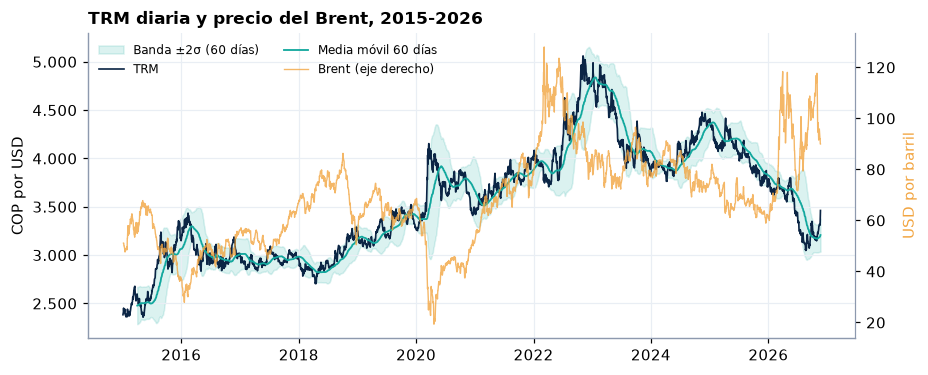

In [9]:
# Nivel de la TRM con media móvil de 60 días y bandas de dos desviaciones
serie = trm[["trm"]].copy()
serie["media_movil"] = serie["trm"].rolling(60).mean()
serie["desv"] = serie["trm"].rolling(60).std()
serie["banda_superior"] = serie["media_movil"] + 2 * serie["desv"]
serie["banda_inferior"] = serie["media_movil"] - 2 * serie["desv"]

fig, eje = plt.subplots(figsize=(9, 3.6))
eje.fill_between(serie.index, serie["banda_inferior"], serie["banda_superior"], color=TURQUESA, alpha=0.15, label="Banda ±2σ (60 días)")
eje.plot(serie.index, serie["trm"], color=AZUL, lw=1.1, label="TRM")
eje.plot(serie.index, serie["media_movil"], color=TURQUESA, lw=1.2, label="Media móvil 60 días")
eje2 = eje.twinx()
eje2.plot(panel_diario.index, panel_diario["brent"], color=AMBAR, lw=0.9, alpha=0.8, label="Brent (eje derecho)")
eje2.set_ylabel("USD por barril", color=AMBAR)
eje2.spines["right"].set_visible(True)
eje2.grid(False)
eje.set_ylabel("COP por USD")
eje.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", ".")))
eje.set_title("TRM diaria y precio del Brent, 2015-2026")
lineas = eje.get_legend_handles_labels()[0] + eje2.get_legend_handles_labels()[0]
etiquetas = eje.get_legend_handles_labels()[1] + eje2.get_legend_handles_labels()[1]
eje.legend(lineas, etiquetas, loc="upper left", ncol=2, fontsize=8)
guardar(fig, "f1_trm_brent")
plt.show()

**Lectura.** Los dos grandes saltos del dólar, en 2015 y en marzo de 2020, coinciden con desplomes del Brent. En 2026 ocurre lo contrario, el petróleo sube por encima de 100 dólares y la TRM cae hasta la zona de 3.050 pesos. Las bandas de dos desviaciones muestran que la serie las rompe con frecuencia, una señal de que los movimientos grandes no son raros.

      media_diaria: 0.00013
       desv_diaria: 0.00850
         vol_anual: 0.13093
         asimetria: 0.30676
   curtosis_exceso: 2.26453
     jarque_bera_p: 0.00000
          peor_dia: -0.03590
         mejor_dia: 0.05931
       obs_anuales: 237.00000


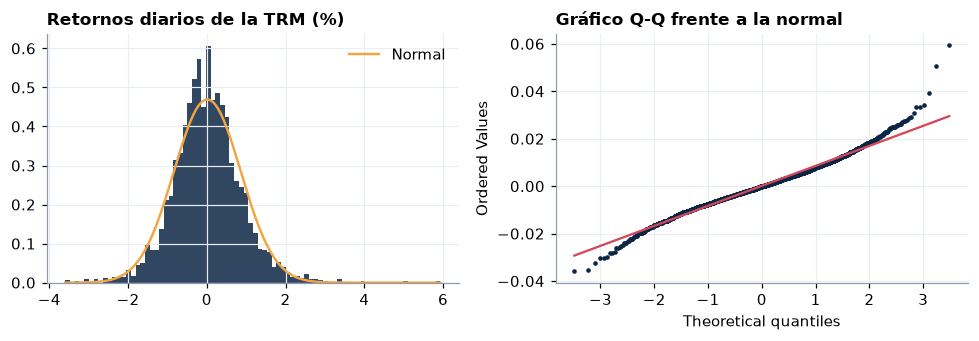

In [10]:
# Retornos diarios: distribución, colas y normalidad
r = trm["retorno"].dropna()
obs_anuales = len(r.loc["2016":"2025"]) / 10
estad_retornos = {
    "media_diaria": r.mean(), "desv_diaria": r.std(),
    "vol_anual": r.std() * np.sqrt(obs_anuales), "asimetria": stats.skew(r),
    "curtosis_exceso": stats.kurtosis(r), "jarque_bera_p": stats.jarque_bera(r).pvalue,
    "peor_dia": r.min(), "mejor_dia": r.max(), "obs_anuales": obs_anuales,
}
for clave, valor in estad_retornos.items():
    print(f"{clave:>18}: {valor:.5f}")

fig, ejes = plt.subplots(1, 2, figsize=(9, 3.2))
ejes[0].hist(r * 100, bins=80, color=AZUL, alpha=0.85, density=True)
x = np.linspace(r.min() * 100, r.max() * 100, 300)
ejes[0].plot(x, stats.norm.pdf(x, r.mean() * 100, r.std() * 100), color=AMBAR, lw=1.6, label="Normal")
ejes[0].set_title("Retornos diarios de la TRM (%)")
ejes[0].legend()
stats.probplot(r, dist="norm", plot=ejes[1])
ejes[1].get_lines()[0].set(color=AZUL, markersize=2)
ejes[1].get_lines()[1].set(color=ROJO)
ejes[1].set_title("Gráfico Q-Q frente a la normal")
plt.tight_layout()
plt.show()

**Lectura.** El retorno diario promedio es casi cero, pero la volatilidad anualizada ronda el 13 %. La curtosis en exceso de 2,3 y el p-valor de Jarque-Bera prácticamente nulo indican colas más pesadas que las de una normal, algo que el gráfico Q-Q deja ver en los extremos. Por eso la simulación usa una distribución t de Student y no una normal.

In [11]:
# Volatilidad móvil anualizada a 21 y 63 días
volatilidad = pd.DataFrame({
    "vol_21d": r.rolling(21).std() * np.sqrt(obs_anuales),
    "vol_63d": r.rolling(63).std() * np.sqrt(obs_anuales),
})
print(volatilidad.describe().round(4))
print("Volatilidad a 21 días más reciente:", round(volatilidad["vol_21d"].iloc[-1], 4))

         vol_21d    vol_63d
count  2794.0000  2752.0000
mean      0.1227     0.1258
std       0.0430     0.0349
min       0.0454     0.0622
25%       0.0919     0.0979
50%       0.1151     0.1183
75%       0.1463     0.1484
max       0.3505     0.2423
Volatilidad a 21 días más reciente: 0.1192


**Lectura.** La volatilidad de 21 días se ha movido entre 4,5 % y 35 % anual, con el pico en marzo de 2020. Ese rango tan amplio confirma que suponer una volatilidad fija sería un error, y justifica el modelo GARCH de la sección 4.

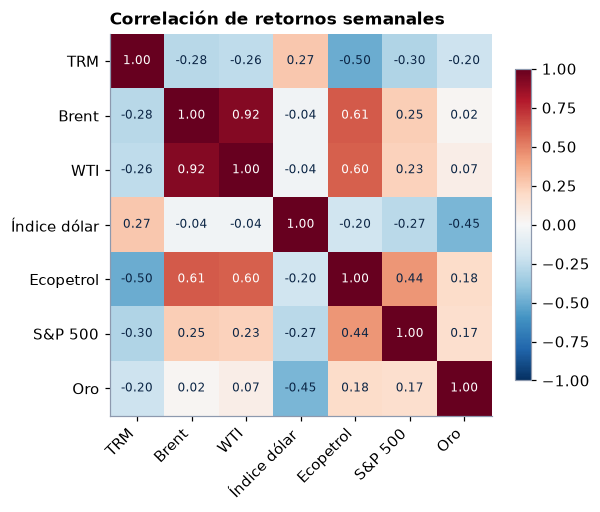

Ecopetrol      -0.495143
S&P 500        -0.299152
Brent          -0.276191
WTI            -0.255213
Oro            -0.204178
Índice dólar    0.271528
TRM             1.000000
Name: TRM, dtype: float64

In [12]:
# Correlaciones de los retornos semanales
etiquetas_corr = {"trm": "TRM", "brent": "Brent", "wti": "WTI", "indice_dolar": "Índice dólar",
                  "ecopetrol_adr": "Ecopetrol", "sp500": "S&P 500", "oro": "Oro"}
corr = retornos_semanales[list(etiquetas_corr)].rename(columns=etiquetas_corr).corr()
fig, eje = plt.subplots(figsize=(5.6, 4.6))
imagen = eje.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
eje.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
eje.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        eje.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                 color="white" if abs(corr.iloc[i, j]) > 0.5 else AZUL)
eje.grid(False)
eje.set_title("Correlación de retornos semanales")
fig.colorbar(imagen, shrink=0.8)
plt.show()
corr["TRM"].sort_values()

**Lectura.** La TRM se mueve en contra de Ecopetrol (−0,50), del S&P 500 (−0,30) y del Brent (−0,28), y a favor del índice dólar (0,27). Cuando el petróleo o el apetito por riesgo caen, el peso se debilita, y cuando el dólar se fortalece en el mundo también lo hace frente al peso.

         brent  indice_dolar
count  569.000       569.000
mean    -0.243         0.252
std      0.168         0.184
min     -0.659        -0.198
25%     -0.373         0.131
50%     -0.246         0.269
75%     -0.128         0.395
max      0.176         0.629


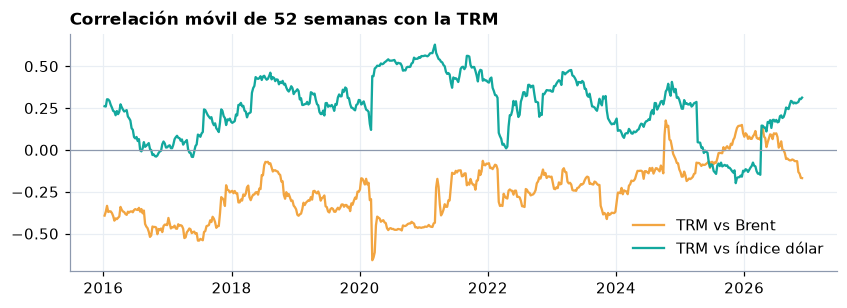

In [13]:
# Correlación móvil de 52 semanas entre la TRM y el Brent y el índice dólar
corr_movil = pd.DataFrame({
    "brent": retornos_semanales["trm"].rolling(52).corr(retornos_semanales["brent"]),
    "indice_dolar": retornos_semanales["trm"].rolling(52).corr(retornos_semanales["indice_dolar"]),
}).dropna()
print(corr_movil.describe().round(3))
fig, eje = plt.subplots(figsize=(9, 2.8))
eje.plot(corr_movil.index, corr_movil["brent"], color=AMBAR, label="TRM vs Brent")
eje.plot(corr_movil.index, corr_movil["indice_dolar"], color=TURQUESA, label="TRM vs índice dólar")
eje.axhline(0, color=GRIS, lw=0.8)
eje.set_title("Correlación móvil de 52 semanas con la TRM")
eje.legend()
plt.show()

**Lectura.** La correlación móvil con el Brent oscila entre −0,66 y 0,18 y su mediana es −0,25. La relación existe pero no es estable, así que el petróleo sirve para entender el contexto y no para fijar un pronóstico mecánico del dólar.

In [14]:
# Estacionalidad: retorno mensual promedio por mes calendario
retornos_mensuales = np.log(panel_mensual["trm"]).diff().dropna()
estacionalidad = retornos_mensuales.groupby(retornos_mensuales.index.month).agg(["mean", "std", "count"])
prueba_kw = stats.kruskal(*[g.values for _, g in retornos_mensuales.groupby(retornos_mensuales.index.month)])
print(estacionalidad.round(4))
print(f"Kruskal-Wallis entre meses: estadístico {prueba_kw.statistic:.2f}, p = {prueba_kw.pvalue:.3f}")

         mean     std  count
fecha                       
1     -0.0061  0.0369     11
2      0.0066  0.0220     12
3     -0.0002  0.0570     12
4     -0.0036  0.0358     12
5      0.0039  0.0418     12
6     -0.0010  0.0448     12
7      0.0058  0.0535     12
8      0.0128  0.0381     12
9      0.0045  0.0218     12
10     0.0067  0.0451     12
11     0.0169  0.0460     12
12    -0.0193  0.0293     11
Kruskal-Wallis entre meses: estadístico 7.07, p = 0.794


**Lectura.** Noviembre muestra el mayor retorno promedio y diciembre el menor, pero la prueba de Kruskal-Wallis (p = 0,79) no encuentra diferencias significativas entre meses. No hay una estacionalidad que la empresa pueda aprovechar para escoger el mes de pago.

In [15]:
# TRM oficial frente a COP=X de Yahoo
contraste_limpio = contraste.drop(atipicos_yahoo.index)
dif = contraste_limpio["diferencia"]
print(f"Diferencia media {dif.mean():.4%}, absoluta media {dif.abs().mean():.4%}, correlación de niveles {contraste_limpio['trm'].corr(contraste_limpio['usdcop_yahoo']):.4f}")

resultados["eda"] = {
    "vol_anual": estad_retornos["vol_anual"], "curtosis": estad_retornos["curtosis_exceso"],
    "asimetria": estad_retornos["asimetria"], "jb_p": estad_retornos["jarque_bera_p"],
    "peor_dia": estad_retornos["peor_dia"], "mejor_dia": estad_retornos["mejor_dia"],
    "vol_21d_actual": volatilidad["vol_21d"].iloc[-1],
    "vol_21d_max": volatilidad["vol_21d"].max(), "fecha_vol_max": str(volatilidad["vol_21d"].idxmax().date()),
    "corr_brent": corr.loc["TRM", "Brent"], "corr_dxy": corr.loc["TRM", "Índice dólar"],
    "corr_ecopetrol": corr.loc["TRM", "Ecopetrol"], "corr_sp500": corr.loc["TRM", "S&P 500"],
    "corr_movil_brent_min": corr_movil["brent"].min(), "corr_movil_brent_max": corr_movil["brent"].max(),
    "kw_p": prueba_kw.pvalue, "dif_trm_yahoo_abs": dif.abs().mean(),
    "trm_min": trm["trm"].min(), "fecha_trm_min": str(trm["trm"].idxmin().date()),
    "trm_max": trm["trm"].max(), "fecha_trm_max": str(trm["trm"].idxmax().date()),
}

Diferencia media -0.1843%, absoluta media 0.4558%, correlación de niveles 0.9993


**Lectura.** Sin los registros erróneos, `COP=X` y la TRM tienen una correlación de 0,999 y difieren en promedio 0,46 % en valor absoluto. La TRM es la tasa con la que se liquidan las importaciones, así que es la serie principal del análisis.

## 4. Modelado

### 4.1 Regresión del retorno del dólar

Se estima por mínimos cuadrados ordinarios el retorno semanal de la TRM contra los retornos del Brent, del índice dólar y del S&P 500, con errores estándar robustos (HAC). En retornos logarítmicos los coeficientes se leen como elasticidades, igual que en el modelo log-log.

In [16]:
# Regresión lineal de retornos semanales con errores HAC
X = sm.add_constant(retornos_semanales[["brent", "indice_dolar", "sp500"]])
modelo_retornos = sm.OLS(retornos_semanales["trm"], X).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
print(modelo_retornos.summary())

                            OLS Regression Results                            
Dep. Variable:                    trm   R-squared:                       0.175
Model:                            OLS   Adj. R-squared:                  0.171
Method:                 Least Squares   F-statistic:                     25.98
Date:                Sun, 22 Nov 2026   Prob (F-statistic):           7.81e-16
Time:                        19:09:59   Log-Likelihood:                 1583.3
No. Observations:                 620   AIC:                            -3159.
Df Residuals:                     616   BIC:                            -3141.
Df Model:                           3                                         
Covariance Type:                  HAC                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.0009      0.001      1.345   

**Lectura.** Los tres factores son significativos al 1 %. Una subida de 10 % en el Brent se asocia con una caída de 0,8 % en la TRM esa semana, una subida de 10 % en el índice dólar con un aumento de 4,6 %, y una subida del S&P 500 con una caída de 1,7 %. El R² de 0,175 indica que estos factores explican una parte modesta del movimiento semanal. El resto depende de factores locales y de choques difíciles de anticipar.

In [17]:
# Modelo log-log en niveles mensuales y prueba de cointegración de Engle-Granger
niveles = np.log(panel_mensual[["trm", "brent", "indice_dolar"]]).dropna()
modelo_loglog = sm.OLS(niveles["trm"], sm.add_constant(niveles[["brent", "indice_dolar"]])).fit()
adf_residuos = adfuller(modelo_loglog.resid, autolag="AIC")
print(modelo_loglog.summary().tables[1])
print(f"R² = {modelo_loglog.rsquared:.3f}. ADF de residuos: estadístico {adf_residuos[0]:.3f}, p = {adf_residuos[1]:.3f}")

resultados["regresion"] = {
    "beta_brent": modelo_retornos.params["brent"], "p_brent": modelo_retornos.pvalues["brent"],
    "beta_dxy": modelo_retornos.params["indice_dolar"], "p_dxy": modelo_retornos.pvalues["indice_dolar"],
    "beta_sp500": modelo_retornos.params["sp500"], "p_sp500": modelo_retornos.pvalues["sp500"],
    "r2": modelo_retornos.rsquared, "n": int(modelo_retornos.nobs),
    "loglog_brent": modelo_loglog.params["brent"], "loglog_dxy": modelo_loglog.params["indice_dolar"],
    "loglog_r2": modelo_loglog.rsquared, "adf_p": adf_residuos[1],
}

                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -0.3010      1.101     -0.273      0.785      -2.478       1.876
brent            0.0857      0.040      2.124      0.035       0.006       0.166
indice_dolar     1.7665      0.252      7.001      0.000       1.268       2.265
R² = 0.358. ADF de residuos: estadístico -2.832, p = 0.054


**Lectura.** En niveles la elasticidad al índice dólar es alta (1,77) y la del Brent es pequeña. El ADF de los residuos da p = 0,054, en el límite del 5 %, por lo que no se puede afirmar con seguridad que exista una relación de largo plazo estable. Por eso las conclusiones se apoyan en el modelo de retornos y no en el de niveles.

### 4.2 Volatilidad condicional con GJR-GARCH

La volatilidad del dólar no es constante, se agrupa en episodios. Se prueba primero si hay efectos ARCH y luego se estima un GJR-GARCH(1,1) con innovaciones t de Student. El término de asimetría permite comprobar si los choques al alza del dólar (depreciación del peso) elevan más la volatilidad que los choques a la baja. El modelo se usa después para simular la TRM a 3 y 6 meses.

In [18]:
# Prueba de efectos ARCH y estimación del GJR-GARCH(1,1) con distribución t
prueba_arch = het_arch(r * 100, nlags=10)
print(f"Prueba LM de efectos ARCH: estadístico {prueba_arch[0]:.1f}, p = {prueba_arch[1]:.2e}")
modelo_garch = arch_model(r * 100, mean="Zero", vol="GARCH", p=1, o=1, q=1, dist="t")
ajuste_garch = modelo_garch.fit(disp="off")
print(ajuste_garch.summary())

Prueba LM de efectos ARCH: estadístico 244.5, p = 7.75e-47
                        Zero Mean - GJR-GARCH Model Results                         
Dep. Variable:                      retorno   R-squared:                       0.000
Mean Model:                       Zero Mean   Adj. R-squared:                  0.000
Vol Model:                        GJR-GARCH   Log-Likelihood:               -3346.59
Distribution:      Standardized Student's t   AIC:                           6703.18
Method:                  Maximum Likelihood   BIC:                           6732.89
                                              No. Observations:                 2814
Date:                      Sun, Nov 22 2026   Df Residuals:                     2814
Time:                              19:09:59   Df Model:                            0
                               Volatility Model                               
                 coef    std err          t      P>|t|        95.0% Conf. Int.
------------------

**Lectura.** La prueba LM confirma efectos ARCH muy fuertes. En el modelo, α y β son significativos y suman casi uno, señal de alta persistencia. El coeficiente de asimetría γ es negativo y significativo. En `arch` ese término se activa con retornos negativos (peso que se aprecia), así que un γ negativo indica que las subidas del dólar elevan más la volatilidad que las bajadas. Para el importador es una mala noticia porque el riesgo crece justo cuando el dólar se encarece. Los grados de libertad cercanos a 10 confirman colas pesadas.

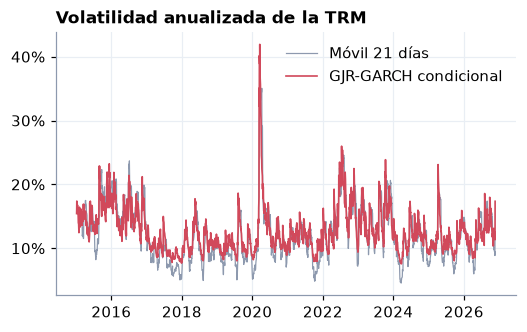

Persistencia 0.9725, vida media de un choque 24.8 días hábiles
Volatilidad condicional actual 17.35%, EWMA actual 14.93%


In [19]:
# Volatilidad condicional frente a la volatilidad móvil y comparación con EWMA
vol_garch = ajuste_garch.conditional_volatility / 100 * np.sqrt(obs_anuales)
vol_ewma = np.sqrt((r ** 2).ewm(alpha=1 - 0.94).mean()) * np.sqrt(obs_anuales)
persistencia = ajuste_garch.params["alpha[1]"] + ajuste_garch.params["beta[1]"] + ajuste_garch.params["gamma[1]"] / 2
vida_media = np.log(0.5) / np.log(persistencia)

fig, eje = plt.subplots(figsize=(5.4, 3.1))
eje.plot(volatilidad.index, volatilidad["vol_21d"], color=GRIS, lw=0.8, label="Móvil 21 días")
eje.plot(vol_garch.index, vol_garch, color=ROJO, lw=1.1, label="GJR-GARCH condicional")
eje.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
eje.set_title("Volatilidad anualizada de la TRM")
eje.legend()
guardar(fig, "f2_volatilidad")
plt.show()
print(f"Persistencia {persistencia:.4f}, vida media de un choque {vida_media:.1f} días hábiles")
print(f"Volatilidad condicional actual {vol_garch.iloc[-1]:.2%}, EWMA actual {vol_ewma.iloc[-1]:.2%}")

resultados["garch"] = {
    "omega": ajuste_garch.params["omega"], "alpha": ajuste_garch.params["alpha[1]"],
    "gamma": ajuste_garch.params["gamma[1]"], "beta": ajuste_garch.params["beta[1]"],
    "nu": ajuste_garch.params["nu"], "p_gamma": ajuste_garch.pvalues["gamma[1]"],
    "persistencia": persistencia, "vida_media": vida_media,
    "vol_actual": vol_garch.iloc[-1], "vol_ewma": vol_ewma.iloc[-1],
    "arch_lm_p": prueba_arch[1],
}

**Lectura.** Un choque de volatilidad tarda unos 25 días hábiles en reducirse a la mitad. La volatilidad condicional de hoy (17,4 %) está por encima del promedio histórico porque la TRM subió cerca de 4 % en los últimos días, y el modelo traslada ese aumento a la simulación de los próximos meses.

## 5. Evaluación de decisiones

### 5.1 Precio del forward

El forward de compra de dólares se aproxima con la paridad cubierta de tasas de interés. Como la tasa en pesos es mayor que la tasa en dólares, el forward queda por encima de la TRM de hoy. A eso se suma un recargo del banco.

$$F = S_0 \left(\frac{1 + i_{COP}}{1 + i_{USD}}\right)^{T} (1 + m)$$

In [20]:
# Parámetros de mercado a la fecha de decisión
fecha_decision = trm.index.max()
spot = trm["trm"].iloc[-1]
tasa_cop = bis["tasa_banrep"].iloc[-1] / 100
tasa_usd = bis["tasa_fed"].iloc[-1] / 100
inicio_presupuesto = fecha_decision - pd.DateOffset(months=supuestos["meses_presupuesto"])
presupuesto = trm.loc[trm.index > inicio_presupuesto, "trm"].mean()


def precio_forward(spot, tasa_cop, tasa_usd, meses, margen_banco=0.0):
    """Forward teórico por paridad cubierta de tasas más el recargo del banco."""
    return spot * ((1 + tasa_cop) / (1 + tasa_usd)) ** (meses / 12) * (1 + margen_banco)


forwards = {m: precio_forward(spot, tasa_cop, tasa_usd, m, supuestos["margen_banco"]) for m in (3, 6)}
print(f"Fecha de decisión {fecha_decision.date()}, TRM {cop(spot, 2)}")
print(f"Tasa Banco de la República {tasa_cop:.2%} ({bis.index[-1]:%Y-%m}), tasa Fed {tasa_usd:.3%}")
print(f"TRM presupuestada (promedio {supuestos['meses_presupuesto']} meses): {cop(presupuesto, 2)}")
for m, f in forwards.items():
    print(f"Forward {m} meses: {cop(f, 2)}  ({f / spot - 1:.2%} sobre la TRM)")

Fecha de decisión 2026-11-21, TRM $ 3.461,92
Tasa Banco de la República 12.25% (2026-10), tasa Fed 3.875%
TRM presupuestada (promedio 12 meses): $ 3.489,79
Forward 3 meses: $ 3.534,98  (2.11% sobre la TRM)
Forward 6 meses: $ 3.604,17  (4.11% sobre la TRM)


**Lectura.** Con la tasa del Banco de la República en 12,25 % y la de la Fed en 3,875 %, el diferencial de 8,4 puntos hace que el forward a 3 meses cueste 2,1 % más que la TRM de hoy y el de 6 meses 4,1 % más. Ambos quedan por encima de la TRM presupuestada (promedio de los últimos 12 meses), de modo que cubrir garantiza un costo algo mayor al presupuesto a cambio de eliminar la incertidumbre.

### 5.2 Simulación Monte Carlo de la TRM

Se simulan 10.000 trayectorias diarias con el GJR-GARCH estimado, con semilla fija. El escenario base supone que el retorno esperado del dólar es cero (paseo aleatorio), que es lo que mejor ha funcionado empíricamente para pronosticar tipos de cambio. Como contraste se evalúan dos derivas alternativas, la tendencia histórica 2015-2026 y la deriva implícita en el forward.

Para validar la simulación se repite el ejercicio con el método de la clase, una distribución triangular de la variación de la TRM con mínimo, valor más probable y máximo tomados de la historia.

In [21]:
# Simulación de trayectorias con el GJR-GARCH (10.000 escenarios, semilla fija)
pasos = {3: round(obs_anuales * 3 / 12), 6: round(obs_anuales * 6 / 12)}
nu = ajuste_garch.params["nu"]
generador = np.random.default_rng(SEMILLA)


def innovaciones_t(n):
    """Innovaciones t de Student estandarizadas con semilla fija."""
    return generador.standard_t(nu, size=n) * np.sqrt((nu - 2) / nu)


pronostico = ajuste_garch.forecast(horizon=pasos[6], method="simulation", simulations=N_SIM,
                                   reindex=False, rng=innovaciones_t)
trayectorias = pronostico.simulations.values[-1] / 100
acumulado = trayectorias.cumsum(axis=1)
retorno_sim = {m: acumulado[:, pasos[m] - 1] for m in (3, 6)}

deriva_historica = r.mean()
derivas = {
    "Paseo aleatorio": 0.0,
    "Tendencia histórica": deriva_historica,
    "Paridad de tasas": np.log((1 + tasa_cop) / (1 + tasa_usd)) / obs_anuales,
}


def trm_simulada(meses, deriva=0.0):
    """TRM al vencimiento para cada escenario simulado."""
    return spot * np.exp(retorno_sim[meses] + deriva * pasos[meses])


tabla_sim = []
for m in (3, 6):
    for nombre, mu in derivas.items():
        s = trm_simulada(m, mu)
        tabla_sim.append({"plazo": m, "deriva": nombre, "media": s.mean(), "p5": np.percentile(s, 5),
                          "mediana": np.median(s), "p95": np.percentile(s, 95),
                          "prob_sobre_forward": (s > forwards[m]).mean(),
                          "prob_sobre_presupuesto": (s > presupuesto).mean()})
tabla_sim = pd.DataFrame(tabla_sim)
print(f"Pasos simulados: {pasos}")
tabla_sim.round(3)

Pasos simulados: {3: 59, 6: 118}


,plazo,deriva,media,p5,mediana,p95,prob_sobre_forward,prob_sobre_presupuesto
0,3,Paseo aleatorio,3470.751,3074.184,3445.115,3946.487,0.369,0.432
1,3,Tendencia histórica,3498.023,3098.340,3472.185,3977.497,0.405,0.473
2,3,Paridad de tasas,3538.399,3134.102,3512.263,4023.407,0.465,0.538
3,6,Paseo aleatorio,3480.326,2956.672,3444.226,4124.013,0.318,0.447
4,6,Tendencia histórica,3535.236,3003.319,3498.566,4189.079,0.380,0.510
5,6,Paridad de tasas,3617.317,3073.051,3579.796,4286.341,0.472,0.612


**Lectura.** En el escenario base la mediana de la TRM simulada queda cerca de la actual, pero el rango del 90 % va de unos 3.070 a 3.950 pesos a 3 meses y de 2.960 a 4.120 a 6 meses. Con paseo aleatorio, la probabilidad de que el dólar termine por encima del forward es 37 % a 3 meses y 32 % a 6 meses, y la de terminar por encima del presupuesto está entre 43 % y 45 %.

In [22]:
# Validación con el método de la clase: distribución triangular de la variación histórica
rng = np.random.default_rng(SEMILLA)
validacion = []
for m in (3, 6):
    variacion_hist = (trm["trm"].shift(-pasos[m]) / trm["trm"] - 1).dropna()
    minimo, moda, maximo = np.percentile(variacion_hist, [2.5, 50, 97.5])
    s_tri = spot * (1 + rng.triangular(minimo, moda, maximo, N_SIM))
    s_garch = trm_simulada(m)
    validacion.append({"plazo": m, "metodo": "Triangular histórica", "min": minimo, "moda": moda, "max": maximo,
                       "p5": np.percentile(s_tri, 5), "mediana": np.median(s_tri), "p95": np.percentile(s_tri, 95)})
    validacion.append({"plazo": m, "metodo": "GJR-GARCH", "min": np.nan, "moda": np.nan, "max": np.nan,
                       "p5": np.percentile(s_garch, 5), "mediana": np.median(s_garch), "p95": np.percentile(s_garch, 95)})
validacion = pd.DataFrame(validacion)
validacion.round(3)

,plazo,metodo,min,moda,max,p5,mediana,p95
0,3,Triangular histórica,-0.115,0.004,0.184,3208.149,3529.691,3920.120
1,3,GJR-GARCH,NaN,NaN,NaN,3074.184,3445.115,3946.487
2,6,Triangular histórica,-0.142,0.010,0.227,3158.250,3561.406,4030.040
3,6,GJR-GARCH,NaN,NaN,NaN,2956.672,3444.226,4124.013


**Lectura.** El método triangular de la clase y el GJR-GARCH dan un percentil 95 muy parecido (3.920 frente a 3.946 a 3 meses). La mediana triangular es un poco mayor porque arrastra la tendencia alcista histórica del dólar, mientras que el GARCH parte de deriva cero. La coincidencia en la cola alta, que es la que preocupa al importador, valida la simulación.

### 5.3 Comparación de estrategias

Para cada escenario simulado se calcula el costo en pesos de la compra según el porcentaje cubierto con forward. El precio de venta se fija con el margen objetivo sobre el costo presupuestado, de modo que el margen realizado cae cuando el costo sube.

In [23]:
# Evaluación de una estrategia de cobertura sobre los escenarios simulados
def evaluar_estrategia(trm_final, forward, cobertura, monto_usd, presupuesto, margen_objetivo, margen_minimo):
    """Métricas de costo, riesgo y margen de una estrategia de cobertura."""
    costo = monto_usd * (cobertura * forward + (1 - cobertura) * trm_final)
    costo_presupuestado = monto_usd * presupuesto
    ventas = costo_presupuestado / (1 - margen_objetivo)
    margen = 1 - costo / ventas
    p95 = np.percentile(costo, 95)
    return {
        "cobertura": cobertura, "costo_esperado": costo.mean(), "costo_p5": np.percentile(costo, 5),
        "costo_p95": p95, "cvar95": costo[costo >= p95].mean(), "desv_costo": costo.std(),
        "desviacion_presupuesto": costo.mean() - costo_presupuestado,
        "prob_superar_presupuesto": (costo > costo_presupuestado * (1 + 1e-9)).mean(),
        "margen_esperado": margen.mean(), "margen_p5": np.percentile(margen, 5),
        "prob_margen_bajo": (margen < margen_minimo).mean(),
        "utilidad_esperada": (ventas - costo).mean(), "prob_perdida": (ventas - costo < 0).mean(),
    }


argumentos = dict(monto_usd=supuestos["monto_usd"], presupuesto=presupuesto,
                  margen_objetivo=supuestos["margen_objetivo"], margen_minimo=supuestos["margen_minimo"])
coberturas = np.round(np.arange(0, 1.0001, 0.05), 2)
curvas = []
for m in (3, 6):
    s = trm_simulada(m)
    for h in coberturas:
        fila = evaluar_estrategia(s, forwards[m], h, **argumentos)
        fila["plazo"] = m
        curvas.append(fila)
curvas = pd.DataFrame(curvas)

# Ahorro esperado de cada estrategia frente a no cubrir
base_sin_cubrir = curvas[curvas["cobertura"] == 0].set_index("plazo")["costo_esperado"]
curvas["ahorro_esperado"] = curvas["plazo"].map(base_sin_cubrir) - curvas["costo_esperado"]
curvas["reduccion_p95"] = curvas["plazo"].map(curvas[curvas["cobertura"] == 0].set_index("plazo")["costo_p95"]) - curvas["costo_p95"]

estrategias = curvas[curvas["cobertura"].isin([0, 0.5, 1])].copy()
vista = estrategias[["plazo", "cobertura", "costo_esperado", "costo_p95", "cvar95", "prob_superar_presupuesto",
                     "prob_margen_bajo", "margen_esperado", "ahorro_esperado"]]
vista.style.format({"costo_esperado": cop, "costo_p95": cop, "cvar95": cop, "ahorro_esperado": cop,
                    "prob_superar_presupuesto": "{:.1%}", "prob_margen_bajo": "{:.1%}",
                    "margen_esperado": "{:.1%}", "cobertura": "{:.0%}"})

,plazo,cobertura,costo_esperado,costo_p95,cvar95,prob_superar_presupuesto,prob_margen_bajo,margen_esperado,ahorro_esperado
0,3,0%,$ 867.687.788,$ 986.621.709,$ 1.038.157.325,43.2%,4.8%,25.4%,$ 0
10,3,50%,$ 875.716.240,$ 935.183.200,$ 960.951.009,50.1%,0.6%,24.7%,$ -8.028.452
20,3,100%,$ 883.744.692,$ 883.744.692,$ 883.744.692,100.0%,0.0%,24.0%,$ -16.056.904
21,6,0%,$ 870.081.586,$ 1.031.003.347,$ 1.099.250.721,44.7%,9.4%,25.2%,$ 0
31,6,50%,$ 885.562.427,$ 966.023.308,$ 1.000.146.995,58.9%,2.5%,23.9%,$ -15.480.841
41,6,100%,$ 901.043.268,$ 901.043.268,$ 901.043.268,100.0%,0.0%,22.5%,$ -30.961.683


**Lectura.** Cubrir el 100 % elimina la dispersión del costo pero lo fija por encima del presupuesto, porque se paga el diferencial de tasas. No cubrir tiene el menor costo esperado pero deja abierta una cola en la que el costo supera los 1.000 millones de pesos a 6 meses.

In [24]:
# Regla de decisión: la cobertura más barata que mantiene el riesgo de margen bajo dentro de la tolerancia
def cobertura_optima(tabla, tolerancia):
    """Menor costo esperado sujeto a P(margen < mínimo) <= tolerancia."""
    factibles = tabla[tabla["prob_margen_bajo"] <= tolerancia]
    if factibles.empty:
        return tabla.loc[tabla["prob_margen_bajo"].idxmin()]
    return factibles.loc[factibles["costo_esperado"].idxmin()]


optimas = {m: cobertura_optima(curvas[curvas["plazo"] == m], supuestos["tolerancia_riesgo"]) for m in (3, 6)}
for m, fila in optimas.items():
    print(f"Plazo {m} meses: cubrir {fila['cobertura']:.0%}, costo esperado {cop(fila['costo_esperado'])}, "
          f"P95 {cop(fila['costo_p95'])}, P(margen < mínimo) {fila['prob_margen_bajo']:.2%}")

Plazo 3 meses: cubrir 0%, costo esperado $ 867.687.788, P95 $ 986.621.709, P(margen < mínimo) 4.76%
Plazo 6 meses: cubrir 35%, costo esperado $ 880.918.175, P95 $ 985.517.319, P(margen < mínimo) 4.58%


**Lectura.** Con una tolerancia del 5 %, a 3 meses la probabilidad de que el margen caiga por debajo del 15 % ya está dentro del límite sin cubrir (4,8 %), mientras que a 6 meses llega al 9,4 % y se necesita cubrir el 35 % para bajarla al 4,6 %. A mayor plazo, mayor dispersión del dólar y más valor tiene la cobertura.

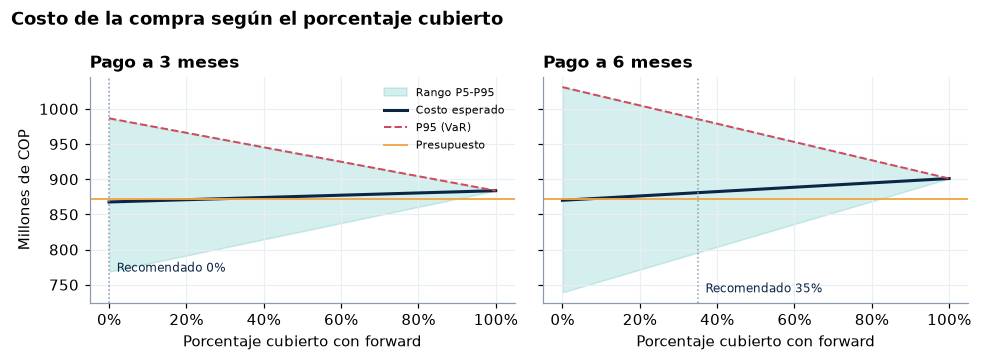

In [25]:
# Figura de decisión: costo esperado y percentil 95 según el porcentaje cubierto
fig, ejes = plt.subplots(1, 2, figsize=(9, 3.3), sharey=True)
for eje, m in zip(ejes, (3, 6)):
    c = curvas[curvas["plazo"] == m]
    eje.fill_between(c["cobertura"], c["costo_p5"] / 1e6, c["costo_p95"] / 1e6, color=TURQUESA, alpha=0.18, label="Rango P5-P95")
    eje.plot(c["cobertura"], c["costo_esperado"] / 1e6, color=AZUL, lw=2, label="Costo esperado")
    eje.plot(c["cobertura"], c["costo_p95"] / 1e6, color=ROJO, lw=1.3, ls="--", label="P95 (VaR)")
    eje.axhline(supuestos["monto_usd"] * presupuesto / 1e6, color=AMBAR, lw=1.2, label="Presupuesto")
    eje.axvline(optimas[m]["cobertura"], color=GRIS, lw=1, ls=":")
    eje.text(optimas[m]["cobertura"] + 0.02, c["costo_p5"].min() / 1e6,
             f"Recomendado {optimas[m]['cobertura']:.0%}", fontsize=8, color=AZUL)
    eje.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    eje.set_title(f"Pago a {m} meses")
    eje.set_xlabel("Porcentaje cubierto con forward")
ejes[0].set_ylabel("Millones de COP")
ejes[0].legend(fontsize=7.5, loc="upper right")
fig.suptitle("Costo de la compra según el porcentaje cubierto", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
guardar(fig, "f3_estrategias")
plt.show()

### 5.4 Análisis de sensibilidad (tornado)

Se mueve una variable a la vez entre su valor mínimo y máximo, con las demás en el caso base, y se mide el efecto sobre la utilidad bruta esperada de la operación con la cobertura recomendada a 6 meses. Las barras se ordenan por rango, con la variable de mayor impacto arriba.

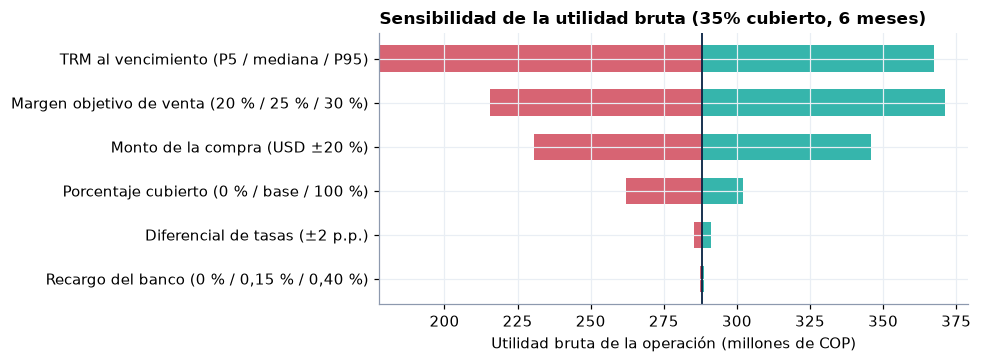

,variable,valor_bajo,valor_alto,utilidad_bajo,utilidad_alto,rango
5,TRM al vencimiento (P5 / mediana / P95),2957.0,4124.0,367440310.0,177747268.0,189693042.0
4,Margen objetivo de venta (20 % / 25 % / 30 %),0.0,0.0,215508684.0,371303049.0,155794364.0
3,Monto de la compra (USD ±20 %),200000.0,300000.0,230570177.0,345855265.0,115285088.0
2,Porcentaje cubierto (0 % / base / 100 %),0.0,1.0,302208092.0,262221318.0,39986773.0
1,Diferencial de tasas (±2 p.p.),0.0,0.0,291034837.0,285415636.0,5619201.0
0,"Recargo del banco (0 % / 0,15 % / 0,40 %)",0.0,0.0,288685060.0,287425489.0,1259571.0


In [26]:
# Tornado sobre la utilidad bruta de la operación
plazo_tornado = 6
cobertura_base = float(optimas[plazo_tornado]["cobertura"])
diferencial_base = tasa_cop - tasa_usd
s_base = trm_simulada(plazo_tornado)
valores_trm = {"min": np.percentile(s_base, 5), "base": np.median(s_base), "max": np.percentile(s_base, 95)}


def utilidad(trm_final=None, monto=supuestos["monto_usd"], diferencial=diferencial_base,
             margen_banco=supuestos["margen_banco"], margen_objetivo=supuestos["margen_objetivo"],
             cobertura=cobertura_base, meses=plazo_tornado):
    """Utilidad bruta en COP para un valor puntual de la TRM al vencimiento."""
    trm_final = valores_trm["base"] if trm_final is None else trm_final
    forward = precio_forward(spot, tasa_usd + diferencial, tasa_usd, meses, margen_banco)
    costo = monto * (cobertura * forward + (1 - cobertura) * trm_final)
    ventas = monto * presupuesto / (1 - margen_objetivo)
    return ventas - costo


escenarios_tornado = {
    "TRM al vencimiento (P5 / mediana / P95)": ("trm_final", valores_trm["min"], valores_trm["base"], valores_trm["max"]),
    "Monto de la compra (USD ±20 %)": ("monto", supuestos["monto_usd"] * 0.8, supuestos["monto_usd"], supuestos["monto_usd"] * 1.2),
    "Margen objetivo de venta (20 % / 25 % / 30 %)": ("margen_objetivo", 0.20, 0.25, 0.30),
    "Porcentaje cubierto (0 % / base / 100 %)": ("cobertura", 0.0, cobertura_base, 1.0),
    "Diferencial de tasas (±2 p.p.)": ("diferencial", diferencial_base - 0.02, diferencial_base, diferencial_base + 0.02),
    "Recargo del banco (0 % / 0,15 % / 0,40 %)": ("margen_banco", 0.0, supuestos["margen_banco"], 0.004),
}
utilidad_base = utilidad()
filas = []
for nombre, (param, bajo, base, alto) in escenarios_tornado.items():
    u_bajo, u_alto = utilidad(**{param: bajo}), utilidad(**{param: alto})
    filas.append({"variable": nombre, "valor_bajo": bajo, "valor_alto": alto,
                  "utilidad_bajo": u_bajo, "utilidad_alto": u_alto, "rango": abs(u_alto - u_bajo)})
tornado = pd.DataFrame(filas).sort_values("rango", ascending=True).reset_index(drop=True)

fig, eje = plt.subplots(figsize=(9, 3.4))
for i, fila in tornado.iterrows():
    menor, mayor = sorted([fila["utilidad_bajo"], fila["utilidad_alto"]])
    eje.barh(i, (utilidad_base - menor) / 1e6, left=menor / 1e6, color=ROJO, alpha=0.85, height=0.6)
    eje.barh(i, (mayor - utilidad_base) / 1e6, left=utilidad_base / 1e6, color=TURQUESA, alpha=0.85, height=0.6)
eje.axvline(utilidad_base / 1e6, color=AZUL, lw=1.2)
eje.margins(x=0.04)
eje.set_yticks(range(len(tornado)), tornado["variable"])
eje.set_xlabel("Utilidad bruta de la operación (millones de COP)")
eje.set_title(f"Sensibilidad de la utilidad bruta ({cobertura_base:.0%} cubierto, {plazo_tornado} meses)")
plt.tight_layout()
guardar(fig, "f4_tornado")
plt.show()
tornado.sort_values("rango", ascending=False).round(0)

**Lectura.** La TRM al vencimiento es la variable que más mueve la utilidad (cerca de 190 millones de pesos entre el P5 y el P95), seguida del margen de venta y del monto. El diferencial de tasas y el recargo del banco, que definen el costo del forward, pesan muy poco. La conclusión del tornado es que el riesgo está en el dólar y no en el precio de la cobertura.

### 5.5 Sensibilidad a la deriva y backtest histórico

La recomendación depende de qué se espere del dólar. Se repite la regla de decisión con las tres derivas y luego se contrasta con lo que habría pasado en la práctica si la empresa hubiera cubierto cada mes desde 2015.

In [27]:
# Cobertura recomendada según la deriva supuesta
sensibilidad_deriva = []
for nombre, mu in derivas.items():
    for m in (3, 6):
        s = trm_simulada(m, mu)
        tabla = pd.DataFrame([evaluar_estrategia(s, forwards[m], h, **argumentos) for h in coberturas])
        opt = cobertura_optima(tabla, supuestos["tolerancia_riesgo"])
        sensibilidad_deriva.append({"deriva": nombre, "plazo": m, "cobertura": opt["cobertura"],
                                    "costo_esperado": opt["costo_esperado"], "prob_margen_bajo": opt["prob_margen_bajo"],
                                    "prob_margen_bajo_sin_cubrir": tabla.loc[0, "prob_margen_bajo"]})
sensibilidad_deriva = pd.DataFrame(sensibilidad_deriva)
sensibilidad_deriva

,deriva,plazo,cobertura,costo_esperado,prob_margen_bajo,prob_margen_bajo_sin_cubrir
0,Paseo aleatorio,3,0.00,8.676878e+08,0.0476,0.0476
1,Paseo aleatorio,6,0.35,8.809182e+08,0.0458,0.0943
2,Tendencia histórica,3,0.10,8.754297e+08,0.0443,0.0562
3,Tendencia histórica,6,0.45,8.915644e+08,0.0402,0.1194
4,Paridad de tasas,3,1.00,8.837447e+08,0.0000,0.0722
5,Paridad de tasas,6,1.00,9.010433e+08,0.0000,0.1638


**Lectura.** La recomendación depende de lo que se espere del dólar. Con paseo aleatorio la cobertura a 6 meses es 35 % y con la tendencia histórica sube a 45 %. A 3 meses pasa de 0 % a 10 %. Si se cree que el dólar subirá al ritmo del diferencial de tasas, lo indicado es cubrir el 100 % en ambos plazos. Por eso la recomendación se expresa como un rango y no como una cifra exacta.

In [28]:
# Backtest: cada mes desde 2015 se compara cubrir al 100 % con forward frente a no cubrir
def backtest(meses):
    """Costo por dólar de cubrir y no cubrir para cada mes histórico."""
    filas = []
    inicios = trm["trm"].groupby(trm.index.to_period("M")).head(1)
    for fecha, s0 in inicios.items():
        fecha_fin = fecha + pd.DateOffset(months=meses)
        if fecha_fin > trm.index.max():
            break
        tasas_mes = bis.loc[:fecha - pd.offsets.MonthEnd(1)].iloc[-1]
        f = precio_forward(s0, tasas_mes["tasa_banrep"] / 100, tasas_mes["tasa_fed"] / 100, meses, supuestos["margen_banco"])
        s_t = trm["trm"].asof(fecha_fin)
        filas.append({"fecha": fecha, "plazo": meses, "trm_inicial": s0, "forward": f, "trm_final": s_t,
                      "ahorro_cubrir_pct": (s_t - f) / s0})
    return pd.DataFrame(filas)


historico = pd.concat([backtest(3), backtest(6)], ignore_index=True)
resumen_backtest = historico.groupby("plazo").agg(
    meses=("ahorro_cubrir_pct", "size"),
    prob_cubrir_gano=("ahorro_cubrir_pct", lambda x: (x > 0).mean()),
    ahorro_medio=("ahorro_cubrir_pct", "mean"),
    ahorro_mediano=("ahorro_cubrir_pct", "median"),
    peor_sin_cubrir=("ahorro_cubrir_pct", "max"),
    peor_cubriendo=("ahorro_cubrir_pct", "min"),
)
desv = historico.assign(var_sin=lambda d: d["trm_final"] / d["trm_inicial"] - 1,
                        var_con=lambda d: d["forward"] / d["trm_inicial"] - 1).groupby("plazo")[["var_sin", "var_con"]].std()
resumen_backtest = resumen_backtest.join(desv.rename(columns={"var_sin": "desv_sin_cubrir", "var_con": "desv_cubriendo"}))
resumen_backtest

,meses,prob_cubrir_gano,ahorro_medio,ahorro_mediano,peor_sin_cubrir,peor_cubriendo,desv_sin_cubrir,desv_cubriendo
plazo,,,,,,,,
3,140,0.450000,-0.004278,-0.009589,0.239624,-0.159564,0.069555,0.004962
6,137,0.452555,-0.007420,-0.011373,0.248514,-0.202287,0.093480,0.009897


**Lectura.** Con datos reales desde 2015, cubrir con forward resultó más barato que esperar en el 45 % de los meses, y en promedio costó apenas 0,4 % (3 meses) y 0,7 % (6 meses) más por dólar. A cambio, la desviación del costo cae de 9,3 % a 1,0 % a 6 meses, y se evita el peor caso histórico, en el que no cubrir salió 25 % más caro que el forward.

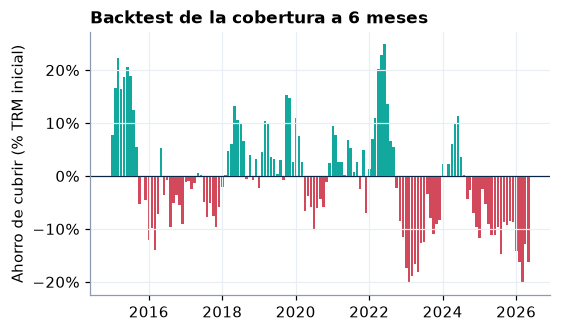

In [29]:
# Figura del backtest a 6 meses
h6 = historico[historico["plazo"] == 6]
fig, eje = plt.subplots(figsize=(5.4, 3.1))
colores = np.where(h6["ahorro_cubrir_pct"] > 0, TURQUESA, ROJO)
eje.bar(h6["fecha"], h6["ahorro_cubrir_pct"], width=25, color=colores)
eje.axhline(0, color=AZUL, lw=0.8)
eje.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
eje.set_title("Backtest de la cobertura a 6 meses")
eje.set_ylabel("Ahorro de cubrir (% TRM inicial)")
guardar(fig, "f5_backtest")
plt.show()

## 6. Recomendación y exportación

In [30]:
# Resumen de la recomendación con las cifras del caso base
plazo_rec = 6
fila_rec = optimas[plazo_rec]
sin_cubrir = curvas[(curvas["plazo"] == plazo_rec) & (curvas["cobertura"] == 0)].iloc[0]
total = curvas[(curvas["plazo"] == plazo_rec) & (curvas["cobertura"] == 1)].iloc[0]
print(f"Recomendación a {plazo_rec} meses: cubrir {fila_rec['cobertura']:.0%} del monto")
print(f"  Costo esperado {cop(fila_rec['costo_esperado'])} frente a {cop(sin_cubrir['costo_esperado'])} sin cubrir")
print(f"  P95 del costo {cop(fila_rec['costo_p95'])} frente a {cop(sin_cubrir['costo_p95'])} sin cubrir")
print(f"  P(margen < mínimo) {fila_rec['prob_margen_bajo']:.2%} frente a {sin_cubrir['prob_margen_bajo']:.2%} sin cubrir")
print(f"  Prima esperada de la cobertura {cop(-fila_rec['ahorro_esperado'])}; reducción del P95 {cop(fila_rec['reduccion_p95'])}")

Recomendación a 6 meses: cubrir 35% del monto
  Costo esperado $ 880.918.175 frente a $ 870.081.586 sin cubrir
  P95 del costo $ 985.517.319 frente a $ 1.031.003.347 sin cubrir
  P(margen < mínimo) 4.58% frente a 9.43% sin cubrir
  Prima esperada de la cobertura $ 10.836.589; reducción del P95 $ 45.486.027


In [31]:
# Exportación de resultados para el documento y el tablero
def a_lista(df):
    """Convierte un DataFrame a registros serializables."""
    return json.loads(df.to_json(orient="records", date_format="iso"))


resultados["mercado"] = {
    "fecha_decision": str(fecha_decision.date()), "spot": spot, "tasa_cop": tasa_cop, "tasa_usd": tasa_usd,
    "mes_tasas": f"{bis.index[-1]:%Y-%m}", "presupuesto": presupuesto,
    "forward_3": forwards[3], "forward_6": forwards[6], "pasos_3": pasos[3], "pasos_6": pasos[6],
    "obs_anuales": obs_anuales, "deriva_historica": deriva_historica,
    "inflacion_col": bis["inflacion_col"].dropna().iloc[-1], "inflacion_eeuu": bis["inflacion_eeuu"].dropna().iloc[-1],
    "brent": panel_diario["brent"].iloc[-1], "indice_dolar": panel_diario["indice_dolar"].iloc[-1],
}
resultados["supuestos"] = supuestos
resultados["simulacion"] = a_lista(tabla_sim)
resultados["validacion"] = a_lista(validacion)
resultados["estrategias"] = a_lista(estrategias)
resultados["optimas"] = {str(m): fila.to_dict() for m, fila in optimas.items()}
resultados["tornado"] = a_lista(tornado.sort_values("rango", ascending=False))
resultados["tornado_base"] = {"utilidad_base": utilidad_base, "plazo": plazo_tornado, "cobertura": cobertura_base}
resultados["sensibilidad_deriva"] = a_lista(sensibilidad_deriva)
resultados["backtest"] = a_lista(resumen_backtest.reset_index())
resultados["semilla"] = SEMILLA
resultados["n_sim"] = N_SIM


def convertir(objeto):
    """Convierte tipos de numpy a tipos nativos de Python."""
    if isinstance(objeto, dict):
        return {k: convertir(v) for k, v in objeto.items()}
    if isinstance(objeto, list):
        return [convertir(v) for v in objeto]
    if isinstance(objeto, (np.integer,)):
        return int(objeto)
    if isinstance(objeto, (np.floating,)):
        return float(objeto)
    return objeto


resultados = convertir(resultados)
with open(RESULTADOS / "resultados.json", "w", encoding="utf-8") as archivo:
    json.dump(resultados, archivo, ensure_ascii=False, indent=2)
with open(DATOS_TABLERO / "parametros.json", "w", encoding="utf-8") as archivo:
    json.dump(resultados, archivo, ensure_ascii=False, indent=2)

# Datos que consume el tablero
serie_tablero = serie[["trm", "media_movil", "banda_superior", "banda_inferior"]].join(
    panel_diario[["brent", "indice_dolar", "usdcop_yahoo"]]).join(
    pd.DataFrame({"vol_21d": volatilidad["vol_21d"], "vol_garch": vol_garch}))
serie_tablero.round(4).to_csv(DATOS_TABLERO / "serie_diaria.csv")
pd.DataFrame({"r_3m": retorno_sim[3], "r_6m": retorno_sim[6]}).round(6).to_csv(DATOS_TABLERO / "simulaciones.csv", index=False)
historico.round(6).to_csv(DATOS_TABLERO / "backtest.csv", index=False)
retornos_semanales.round(6).to_csv(DATOS_TABLERO / "retornos_semanales.csv")
bis.round(4).to_csv(DATOS_TABLERO / "macro_mensual.csv")
print("Archivos exportados:", sorted(p.name for p in DATOS_TABLERO.iterdir()))

Archivos exportados: ['backtest.csv', 'macro_mensual.csv', 'parametros.json', 'retornos_semanales.csv', 'serie_diaria.csv', 'simulaciones.csv']
